# K-Nearest Neighbors (KNN) from Scratch

# Mathematical formulation

## Model Definition

KNN is a **non-parametric** algorithm for supervised learning that simply stores the labeled training examples, during the training phase. For this reason, kNN is also called a **lazy learning** algorithm - it mostly does the work during prediction, not training. Unlike linear/logistic regression, the KNN algorithm does not learn weights and does not use gradient descent

For classification, the most common label among the **k nearest neighbors** becomes the prediction

For example, if the five nearest neighbors have labels `[0, 1, 1, 1, 0]`, the predicted class is `1`

KNN is a **non-parametric**, **lazy learning** algorithm:
- it does not learn weights or a fixed equation
- `fit()` stores the training data
- distances and votes are calculated when making predictions

KNN can also be used for regression by averaging the neighbors' target values

## Distance Metrics

KNN depends on a distance metric to measure how close two data points are

For two samples:

$$
\mathbf{x}_i = (x_{i1}, x_{i2}, \dots, x_{im})
$$

$$
\mathbf{x}_q = (x_{q1}, x_{q2}, \dots, x_{qm})
$$

where:

- $\mathbf{x}_i$ — training sample
- $\mathbf{x}_q$ — query/test sample
- $m$ — number of features

### Euclidean distance
This is the most commonly used distance measure, and it is limited to real-valued vectors. It measures the straight-line distance between two points:
$$
d(\mathbf{x}_q, \mathbf{x}_i) =
\sqrt{\sum_{j=1}^{m}(x_{qj} - x_{ij})^2}
$$

It works well when features are continuous and scaled properly


### Manhattan Distance
Manhattan distance is also called L1 distance. Calculate the distance between real vectors using the sum of their absolute difference:

$$
d(\mathbf{x}_q, \mathbf{x}_i) =
\sum_{j=1}^{m}|x_{qj} - x_{ij}|
$$

Instead of measuring straight-line distance, it measures distance like moving on a grid: left/right/up/down

### Minkowski Distance
Minkowski distance is a general form of Euclidean and Manhattan distance:

$$
d(\mathbf{x}_q, \mathbf{x}_i) =
\left(\sum_{j=1}^{m}|x_{qj} - x_{ij}|^p\right)^{\frac{1}{p}}
$$

where:

- $p = 1$ gives Manhattan distance
- $p = 2$ gives Euclidean distance

### Hamming Distance
Hamming distance is used for categorical, binary, or discrete values. It calculates the distance between binary vectors

$$
d(\mathbf{x}_q, \mathbf{x}_i) =
\sum_{j=1}^{m} I(x_{qj} \neq x_{ij})
$$

where:

- $I(\cdot)$ is an indicator function
- it returns `1` if feature values are different
- it returns `0` if feature values are the same

### Comparison

| Distance  | Formula idea                        | Typical use                          |
| --------- | ----------------------------------- | ------------------------------------ |
| Manhattan | Sum of absolute differences         | Numeric, sparse, tabular data        |
| Minkowski | General distance with parameter (p) | Flexible numeric distance            |
| Hamming   | Count of different positions        | Binary/categorical/discrete features |


## Neighbor Selection

After calculating distances from the query sample to all training samples, KNN selects the `k` samples with the smallest distances

Let the training dataset be:

$$
D = \{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \dots, (\mathbf{x}_n, y_n)\}
$$

For a query sample $\mathbf{x}_q$, calculate:

$$
d(\mathbf{x}_q, \mathbf{x}_i)
$$

for every training sample $\mathbf{x}_i$.

The set of `k` nearest neighbors is:

$$
N_k(\mathbf{x}_q) =
\text{k samples with the smallest } d(\mathbf{x}_q, \mathbf{x}_i)
$$

where:

- $N_k(\mathbf{x}_q)$ — set of nearest neighbors
- $k$ — number of neighbors
- $n$ — number of training samples

## Majority vote



$$\hat{y} = \underset{c \in C}{\arg\max}\;\sum_{i \in N_k(\mathbf{x})}\mathbb{1}(y_i=c)$$

where $C$ is the set of classes and $\mathbb{1}(y_i=c)$ equals 1 when neighbor $i$
belongs to class $c$, and 0 otherwise

We can also return the **fraction of neighbors** belonging to each class:

$$\hat{P}(y=c\mid\mathbf{x}) = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})}\mathbb{1}(y_i=c)$$

These fractions sum to 1, but they are not necessarily calibrated probabilities

## Class Probability Estimates

With uniform voting, KNN estimates the probability of each class as the fraction of the \(k\) nearest neighbors belonging to that class:

$$
\hat{P}(y=c\mid\mathbf{x}_q)=
\frac{1}{k}
\sum_{i\in N_k(\mathbf{x}_q)}
\mathbb{1}(y_i=c)
$$

where:

- $N_k(\mathbf{x}_q)$ is the set of indices of the $k$ nearest neighbors
- $c$ is a class label
- $\mathbb{1}(y_i=c)$ equals $1$ if neighbor $i$ belongs to class $c$, and $0$ otherwise

For example, if the five nearest neighbors have labels `[0, 1, 1, 1, 0]`:

$$
\hat{P}(y=0\mid\mathbf{x}_q)=\frac{2}{5}=0.4
$$

$$
\hat{P}(y=1\mid\mathbf{x}_q)=\frac{3}{5}=0.6
$$

The `predict()` method returns the predicted class, while `predict_proba()` returns the estimated probability of each class

These estimates sum to $1$, but they are not necessarily calibrated probabilities. Here, $0.6$ means that three of the five nearest neighbors belong to class $1$

## Regression

KNN can also be used for regression. With uniform weights, the prediction is the mean of the target values of the \(k\) nearest neighbors:

$$
\hat{y}_q=
\frac{1}{k}
\sum_{i\in N_k(\mathbf{x}_q)}y_i
$$

For example, if the three nearest neighbors have target values `[10, 12, 14]`, the prediction is:

$$
\hat{y}_q=\frac{10+12+14}{3}=12
$$

## Choosing k and scaling features

- **Small k:** predictions depend on a small local neighborhood and can be sensitive to noise
- **Large k:** predictions become smoother and may miss local patterns
- An odd k prevents a voting tie for binary classification with uniform votes. Multiclass voting can still produce ties
- Choose k using validation data or cross-validation, keeping the test set for final evaluation

Distance depends on feature scale. A feature measured in thousands can dominate one measured in decimals. We use `StandardScaler`:

$$
x'_j = \frac{x_j - \mu_j}{\sigma_j}
$$

Fit the scaler **only on training data**, then use the same scaler to transform test data

KNN has no gradient descent, learning rate, epochs, or learned coefficients. The parameter k controls how local the prediction is

# Implementation
> Import of implementation class with consistent API from py file

In [1]:
# Imports
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

# Create folders for saved outputs
os.makedirs("outputs/models", exist_ok=True)
os.makedirs("outputs/plots/knn", exist_ok=True)
os.makedirs("outputs/tables/knn", exist_ok=True)

In [3]:
# Custom
from from_scratch.neighbors.knn import SimpleKNN
from from_scratch.util import train_test_split
from from_scratch.report_utils import classification_metrics_report, plot_confusion_matrix, print_report, build_classification_comparison_df, save_metrics

# Real dataset example

Use the **Breast Cancer Wisconsin** dataset included in scikit-learn

Target labels:
- `0` = malignant
- `1` = benign

There are 569 samples and 30 numeric features. This example demonstrates a binary classification task. The precision, recall, F1, and ROC AUC below treat **benign (1)** as the positive class; the confusion matrices show errors for both classes

In [4]:
# 1 - Load dataset
data = load_breast_cancer()

X_real = data.data
y_real = data.target

print("Feature shape:", X_real.shape)
print("Target shape:", y_real.shape)

df_real = pd.DataFrame(X_real, columns=data.feature_names)
df_real["target"] = y_real
df_real.head()

Feature shape: (569, 30)
Target shape: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
# 2 - Train/test split and scaling
X_train_real, X_test_real, y_train_real, y_test_real = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42#, stratify=y_real # TODO add stratify to implemantation
)

scaler_real = StandardScaler() # TODO write own Scaler
X_train_real_scaled = scaler_real.fit_transform(X_train_real)
X_test_real_scaled = scaler_real.transform(X_test_real)

print("Train shape:", X_train_real_scaled.shape)
print("Test shape:", X_test_real_scaled.shape)

Train shape: (455, 30)
Test shape: (114, 30)


In [6]:
# 3 - Fit the from-scratch model
# k is fixed before evaluation; we do not tune it on the test set
K = 5
scratch_real = SimpleKNN(k=K)
scratch_real.fit(X_train_real_scaled, y_train_real)

y_pred_scratch = scratch_real.predict(X_test_real_scaled)
y_proba_scratch = scratch_real.predict_proba(X_test_real_scaled)[:, 1]

metrics_real_scratch = classification_metrics_report(
    y_test_real, y_pred_scratch, y_proba_scratch
)

print_report("From-scratch KNN (real dataset)", metrics_real_scratch)
print(classification_report(y_test_real, y_pred_scratch))

From-scratch KNN (real dataset)
Accuracy: 0.9386
Precision: 0.9118
Recall: 0.9841
F1_score: 0.9466
ROC_AUC: 0.9516
----------------------------------------
              precision    recall  f1-score   support

           0       0.98      0.88      0.93        51
           1       0.91      0.98      0.95        63

    accuracy                           0.94       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.94      0.94      0.94       114



In [7]:
# 4 - Fit the sklearn baseline with the same distance and voting rule
sklearn_real = KNeighborsClassifier(
    n_neighbors=K, metric="euclidean", weights="uniform", algorithm="brute"
)
sklearn_real.fit(X_train_real_scaled, y_train_real)

y_pred_sklearn = sklearn_real.predict(X_test_real_scaled)
y_proba_sklearn = sklearn_real.predict_proba(X_test_real_scaled)[:, 1]

metrics_real_sklearn = classification_metrics_report(y_test_real, y_pred_sklearn, y_proba_sklearn)
print_report("Sklearn model on real dataset", metrics_real_sklearn)

Sklearn model on real dataset
Accuracy: 0.9386
Precision: 0.9118
Recall: 0.9841
F1_score: 0.9466
ROC_AUC: 0.9516
----------------------------------------


In [8]:
# 5 - Compare results
comparison_real = build_classification_comparison_df(
    scratch_metrics=metrics_real_scratch,
    sklearn_metrics=metrics_real_sklearn
)

comparison_real

,Metric,Scratch,Sklearn
0,Accuracy,0.938596,0.938596
1,Precision,0.911765,0.911765
2,Recall,0.984127,0.984127
3,F1_score,0.946565,0.946565
4,ROC_AUC,0.951603,0.951603


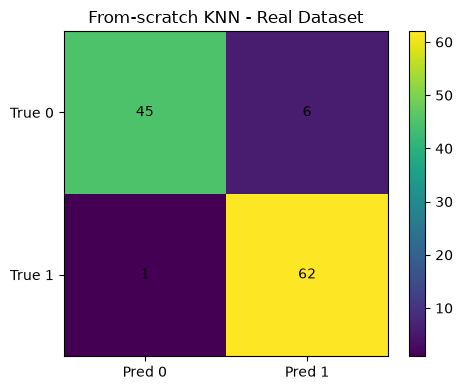

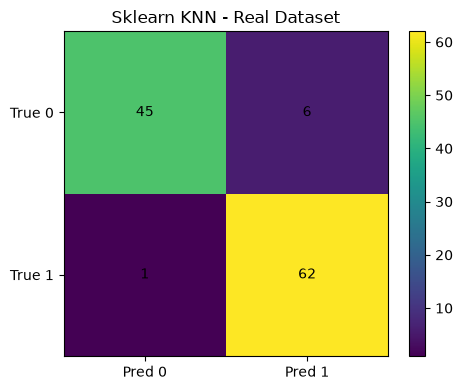

In [9]:
# 6 - Save predictions, tables, and confusion matrices, plot confusion matrices
real_predictions = pd.DataFrame({
    "y_true": y_test_real,
    "y_pred_scratch": y_pred_scratch,
    "y_proba_scratch": y_proba_scratch,
    "y_pred_sklearn": y_pred_sklearn,
    "y_proba_sklearn": y_proba_sklearn,
})

real_predictions.to_csv("outputs/tables/knn/knn_real_dataset_predictions.csv", index=False)
comparison_real.to_csv("outputs/tables/knn/knn_real_dataset_comparison.csv", index=False)

cm_scratch_real = confusion_matrix(y_test_real, y_pred_scratch)
cm_sklearn_real = confusion_matrix(y_test_real, y_pred_sklearn)

plot_confusion_matrix(
    cm_scratch_real, 
    "From-scratch KNN - Real Dataset",
    "outputs/plots/knn/knn_real_dataset_scratch.png"
    )
plot_confusion_matrix(
    cm_sklearn_real, 
    "Sklearn KNN - Real Dataset",
    "outputs/plots/knn/knn_real_dataset_sklearn.png"
    )

In [10]:
print(
    "All predicted labels match:",
    np.array_equal(y_pred_scratch, y_pred_sklearn)
)

print(
    "All predicted probabilities are close:",
    np.allclose(y_proba_scratch, y_proba_sklearn)
)

All predicted labels match: True
All predicted probabilities are close: True


# Save all results summary

In [11]:
knn_results = {
    "parameters": {"k": K, "metric": "euclidean", "weights": "uniform"},
    "real_dataset": {
        "scratch": metrics_real_scratch,
        "sklearn": metrics_real_sklearn,
    }
}

save_metrics("outputs/models/knn_results.json", knn_results)

print("All results saved to outputs/models")

All results saved to outputs/models


# Conclusion
The results of both implementations are similar:
- all predicted labels match exactly
- the probability estimates match within a numerical tolerance
Given the same data, $k$, distance metric, and voting scheme, both implementations execute the exact same algorithm. Since model from scikit-learn was specified `algorithm="brute"`, scikit-learn also performs an exhaustive search of distances, handled by efficient library routines. This affects computational speed

This experiment demonstrates agreement on the evaluated test set; it does not guarantee identical behavior on every dataset. For example, equal-distance neighbors at the selection boundary may be handled differently

However, the main difference is optimization: the library also supports other methods for neighbor searching (KDTree, BallTree), distance-weighted voting, and a wider range of input data formats
